# Anomaly Detection in Physicochemical Data

## 1. Fundamentals of Anomaly Detection: Pure Python Implementation

In this foundational section, we explore statistical anomaly detection from first principles using pure Python, calculating the mean, variance, standard deviation, and Z-scores on a synthetic 1D dataset.

In [1]:
import matplotlib.pyplot as plt

### Synthetic 1D Sensor Measurements
We create a synthetic sequence representing temperature sensor measurements with a clear outlier (`75`).

In [2]:
data = [30,29,31,29,32,30,29,31,29,32,30,29,75]

### Manual Calculation of Mean
Computing the arithmetic mean ($\mu = \frac{1}{N}\sum x_i$) using an accumulator loop.

In [3]:
total = 0
for value in data:
    total += value

mean = total / len(data)

print("Total:",total)
print("Mean:",mean)

Total: 436
Mean: 33.53846153846154


### Manual Calculation of Variance
Computing the sample variance ($\sigma^2 = \frac{1}{N}\sum (x_i - \mu)^2$) by accumulating squared deviations.

In [4]:
squared_total = 0

for value in data:
    difference = value - mean
    squared_difference = difference ** 2
    squared_total += squared_difference

variance = squared_total / len(data)

print("Variance:", variance)

Variance: 144.4023668639053


### Manual Calculation of Standard Deviation
The standard deviation ($\sigma = \sqrt{\sigma^2}$) measures dispersion around the mean in original measurement units.

In [5]:
standard_deviation = variance ** 0.5

print("Standard Deviation:",standard_deviation)

Standard Deviation: 12.016753590879082


### Computing Z-Scores
Standardizing each observation to its standard score: $Z = \frac{x - \mu}{\sigma}$.

In [6]:
for value in data:
    z_score = (value - mean) / standard_deviation

    print(value, "→ Z-Score:",z_score)

30 → Z-Score: -0.2944606887127395
29 → Z-Score: -0.3776778398706876
31 → Z-Score: -0.21124353755479142
29 → Z-Score: -0.3776778398706876
32 → Z-Score: -0.12802638639684336
30 → Z-Score: -0.2944606887127395
29 → Z-Score: -0.3776778398706876
31 → Z-Score: -0.21124353755479142
29 → Z-Score: -0.3776778398706876
32 → Z-Score: -0.12802638639684336
30 → Z-Score: -0.2944606887127395
29 → Z-Score: -0.3776778398706876
75 → Z-Score: 3.4503111133949242


### Identifying Outliers Using the 3-Sigma Rule
Flagging data points where $|Z| > 3$ as statistical anomalies.

In [7]:
anomalies = []

for value in data:
    z_score = (value - mean) / standard_deviation
    if z_score > 3 or z_score < -3:
        anomalies.append(value)

print("Detected anomalies:", anomalies)

Detected anomalies: [75]


### Visualizing the 1D Series
Constructing sample indices to prepare sequence plots.

In [8]:
x = range(1, len(data) + 1)

print(list(x))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


### Plotting 1D Series with Computed Z-Scores
Visualizing sample values alongside individual Z-scores to observe deviations.

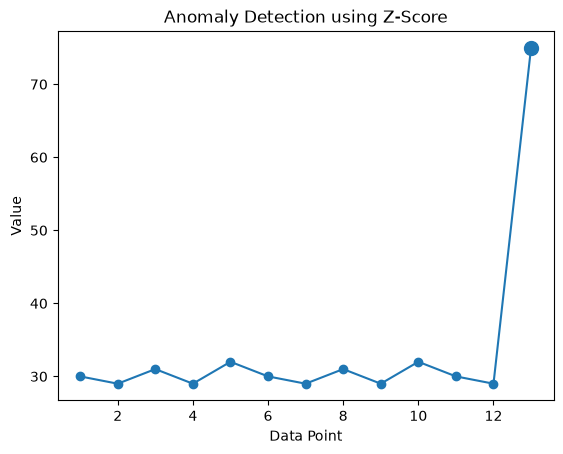

In [9]:
plt.plot(x, data, marker='o')

for i in range(len(data)):
    z_score = (data[i] - mean) / standard_deviation

    if z_score > 3 or z_score < -3:
       plt.scatter(i + 1, data[i], s=100)



plt.xlabel("Data Point")
plt.ylabel("Value")
plt.title("Anomaly Detection using Z-Score")

plt.show()

### Recording Anomaly Index Positions
Identifying and storing index positions where $|Z| > 3$.

In [10]:
anomalies_position  = []


for i in range(len(data)):
    z_score = (data[i] - mean) / standard_deviation

    if z_score > 3 or z_score < -3:
         anomalies_position.append(i)

print("Anomalies Position:",anomalies_position)         

Anomalies Position: [12]


### Extracting Anomalous Values
Recording the exact numeric values flagged by the 3-sigma criterion.

In [11]:
anomaly_values = []

for i in range(len(data)):
    z_score = (data[i] - mean) / standard_deviation

    if z_score > 3 or z_score < -3:
        anomaly_values.append(data[i])

print("Anomaly values:", anomaly_values)

Anomaly values: [75]


### Highlighting Outliers on Sequence Plot
Overlaying anomaly markers in red on the sequence line plot.

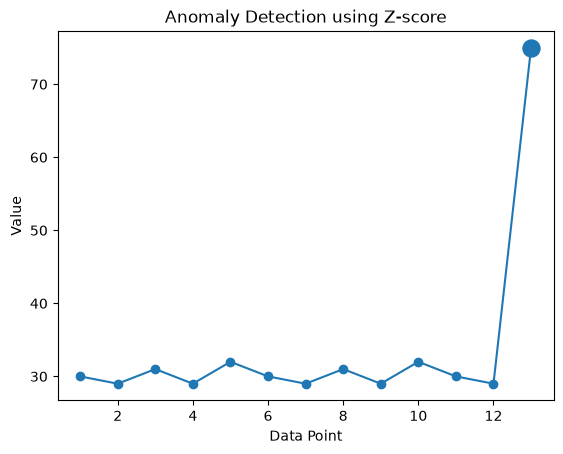

In [12]:
x = range(1, len(data) + 1)

plt.plot(x, data, marker='o')

for i in anomalies_position:
    plt.scatter(i + 1, data[i], s=150)

plt.xlabel("Data Point")
plt.ylabel("Value")
plt.title("Anomaly Detection using Z-score")

plt.show()

## 2. Vectorized Statistical Operations with NumPy

Re-implementing the statistical anomaly detection workflow using NumPy vectorization for performance and conciseness.

In [13]:
import numpy as np

### Converting to NumPy ndarray
Transforming the Python list into a homogeneous contiguous 1D array.

In [14]:
data_array = np.array(data)

print(data_array)

[30 29 31 29 32 30 29 31 29 32 30 29 75]


### Computing Vectorized Mean
Using `np.mean()` to compute the sample mean.

In [15]:
numpy_mean = np.mean(data_array)

print("NumPy Mean:", numpy_mean)

NumPy Mean: 33.53846153846154


### Computing Vectorized Variance and Standard Deviation
Using `np.var()` and `np.std()` to compute dispersion metrics.

In [16]:
numpy_variance = np.var(data_array)

print("NumPy Variance:", numpy_variance)

NumPy Variance: 144.4023668639053


In [17]:
numpy_std = np.std(data_array)

print("NumPy Standard Deviation:", numpy_std)

NumPy Standard Deviation: 12.016753590879082


In [18]:
z_score = (data_array - numpy_mean) / numpy_std

print(z_score)

[-0.29446069 -0.37767784 -0.21124354 -0.37767784 -0.12802639 -0.29446069
 -0.37767784 -0.21124354 -0.37767784 -0.12802639 -0.29446069 -0.37767784
  3.45031111]


In [19]:
anomalies = data_array[np.abs(z_score) > 3]

print("Anomalies:", anomalies)

Anomalies: [75]


### Tabular Data Structures with pandas

In [20]:
import pandas as pd

In [21]:
df = pd.DataFrame({
    "value": data
})

print(df)

    value
0      30
1      29
2      31
3      29
4      32
5      30
6      29
7      31
8      29
9      32
10     30
11     29
12     75


In [22]:
print(df.head())

   value
0     30
1     29
2     31
3     29
4     32


In [23]:
print(df.tail())

    value
8      29
9      32
10     30
11     29
12     75


In [24]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   value   13 non-null     int64
dtypes: int64(1)
memory usage: 236.0 bytes
None


In [25]:
print(df.describe())

           value
count  13.000000
mean   33.538462
std    12.507434
min    29.000000
25%    29.000000
50%    30.000000
75%    31.000000
max    75.000000


In [26]:
pandas_mean = df["value"].mean()

print("Pandas Mean:",pandas_mean)

Pandas Mean: 33.53846153846154


In [27]:
values = df["value"]

print(values)

0     30
1     29
2     31
3     29
4     32
5     30
6     29
7     31
8     29
9     32
10    30
11    29
12    75
Name: value, dtype: int64


### Exploratory Data Analysis (EDA) on Tabular Transactions

In [28]:
import pandas as pd

In [29]:
transactions = {
    "transaction_id":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15],
    "amount": [30,29,31,30,32,29,31,30,28,32,30,29,31,30,150],
    "items": [2,1,3,2,4,1,2,3,1,2,2,1,3,2,15]
}

df_transactions = pd.DataFrame(transactions)

print(df_transactions)

    transaction_id  amount  items
0                1      30      2
1                2      29      1
2                3      31      3
3                4      30      2
4                5      32      4
5                6      29      1
6                7      31      2
7                8      30      3
8                9      28      1
9               10      32      2
10              11      30      2
11              12      29      1
12              13      31      3
13              14      30      2
14              15     150     15


In [30]:
print("Rows and Columns:", df_transactions.shape)

Rows and Columns: (15, 3)


In [31]:
print(df_transactions.columns)

Index(['transaction_id', 'amount', 'items'], dtype='str')


In [32]:
print(df_transactions.dtypes)

transaction_id    int64
amount            int64
items             int64
dtype: object


In [33]:
print(df_transactions.isnull().sum())

transaction_id    0
amount            0
items             0
dtype: int64


In [34]:
print(df_transactions.duplicated().sum())

0


In [35]:
print(df_transactions.describe())

       transaction_id      amount      items
count       15.000000   15.000000  15.000000
mean         8.000000   38.133333   2.933333
std          4.472136   30.967418   3.453087
min          1.000000   28.000000   1.000000
25%          4.500000   29.500000   1.500000
50%          8.000000   30.000000   2.000000
75%         11.500000   31.000000   3.000000
max         15.000000  150.000000  15.000000


In [36]:
print(df_transactions["amount"])

0      30
1      29
2      31
3      30
4      32
5      29
6      31
7      30
8      28
9      32
10     30
11     29
12     31
13     30
14    150
Name: amount, dtype: int64


In [37]:
amount_mean = df_transactions["amount"].mean()

print("Average transaction amount:", amount_mean)

Average transaction amount: 38.13333333333333


In [38]:
import matplotlib.pyplot as plt

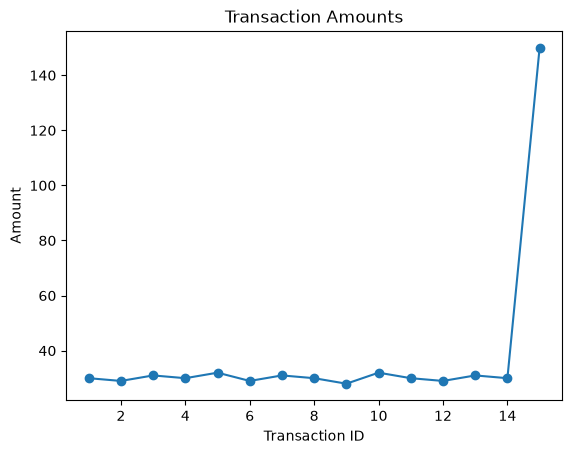

In [39]:
plt.plot(
    df_transactions["transaction_id"],
    df_transactions["amount"], 
    marker='o'
)

plt.xlabel("Transaction ID")
plt.ylabel("Amount")        
plt.title("Transaction Amounts")

plt.show()

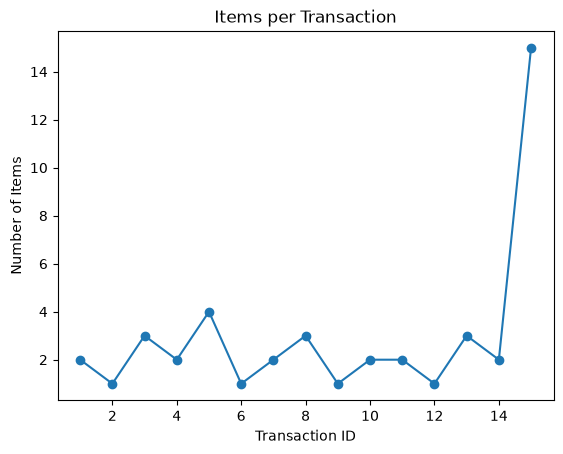

In [40]:
plt.plot(
    df_transactions["transaction_id"],
    df_transactions["items"],
    marker="o"
)

plt.xlabel("Transaction ID")
plt.ylabel("Number of Items")
plt.title("Items per Transaction")

plt.show()

In [41]:
features = df_transactions[["amount","items"]]  

print(features)

    amount  items
0       30      2
1       29      1
2       31      3
3       30      2
4       32      4
5       29      1
6       31      2
7       30      3
8       28      1
9       32      2
10      30      2
11      29      1
12      31      3
13      30      2
14     150     15


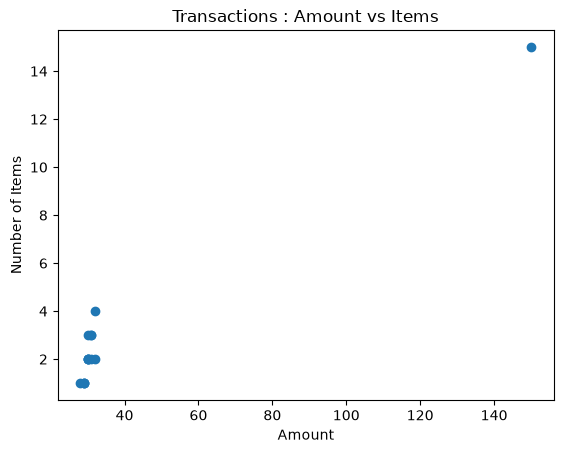

In [42]:
plt.scatter(
    df_transactions["amount"],
    df_transactions["items"]
)

plt.xlabel("Amount")
plt.ylabel("Number of Items")
plt.title("Transactions : Amount vs Items")

plt.show()

In [43]:
x1 = 30
y1 = 2

x2 = 150
y2 = 15

distance = ((x2 - x1) ** 2 + (y2 - y1) ** 2) ** 0.5

print("Distance:", distance)

Distance: 120.70211265756701


In [44]:
amount = df_transactions["amount"].to_numpy()
items = df_transactions["items"].to_numpy()


amount_scaled = (amount - np.mean(amount)) / np.std(amount)
items_scaled = (items - np.mean(items)) / np.std(items)


print(" Scaled Amount:", amount_scaled)
print(" Scaled Items:", items_scaled)

 Scaled Amount: [-0.27185992 -0.30528533 -0.23843452 -0.27185992 -0.20500912 -0.30528533
 -0.23843452 -0.27185992 -0.33871073 -0.20500912 -0.27185992 -0.30528533
 -0.23843452 -0.27185992  3.73918815]
 Scaled Items: [-0.27977627 -0.57953656  0.01998402 -0.27977627  0.31974431 -0.57953656
 -0.27977627  0.01998402 -0.57953656 -0.27977627 -0.27977627 -0.57953656
  0.01998402 -0.27977627  3.61710747]


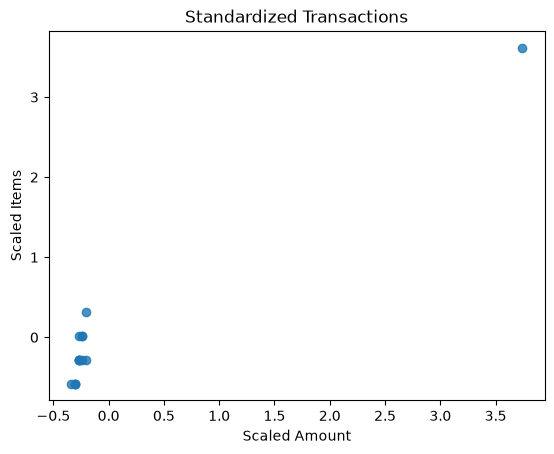

In [45]:
plt.scatter(
    amount_scaled,
    items_scaled,
    color='#1f77b4',
    alpha=0.8
)

plt.xlabel("Scaled Amount")
plt.ylabel("Scaled Items")  
plt.title("Standardized Transactions")
plt.show()

## 3. Tree-Based Anomaly Detection: Isolation Forest

Isolation Forest isolates anomalies by randomly partitioning feature space with orthogonal hyperplanes. Anomalies require fewer recursive splits to isolate than clustered normal points.

In [46]:
from sklearn.ensemble import IsolationForest

In [47]:
print(features)

    amount  items
0       30      2
1       29      1
2       31      3
3       30      2
4       32      4
5       29      1
6       31      2
7       30      3
8       28      1
9       32      2
10      30      2
11      29      1
12      31      3
13      30      2
14     150     15


In [48]:
model = IsolationForest(
    contamination=0.1,
    random_state=42
)

In [49]:
model.fit(features)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [50]:
predictions = model.predict(features)   

print(predictions)

[ 1  1  1  1 -1  1  1  1  1  1  1  1  1  1 -1]


In [51]:
anomalies = features[predictions == -1]
print(anomalies)

    amount  items
4       32      4
14     150     15


In [52]:
scores = model.decision_function(features)
print(scores)

[ 0.20914904  0.13578128  0.14699976  0.20914904 -0.00968132  0.13578128
  0.16641989  0.10742143  0.01452198  0.08497578  0.20914904  0.13578128
  0.14699976  0.20914904 -0.2492463 ]


In [53]:
amount_mean = np.mean(amount)
amount_std = np.std(amount)

amount_z_scores = (amount - amount_mean) / amount_std

print(amount_z_scores)

[-0.27185992 -0.30528533 -0.23843452 -0.27185992 -0.20500912 -0.30528533
 -0.23843452 -0.27185992 -0.33871073 -0.20500912 -0.27185992 -0.30528533
 -0.23843452 -0.27185992  3.73918815]


In [54]:
items_mean = np.mean(items)
items_std = np.std(items)

items_z_scores = (items - items_mean) / items_std
print(items_z_scores)

[-0.27977627 -0.57953656  0.01998402 -0.27977627  0.31974431 -0.57953656
 -0.27977627  0.01998402 -0.57953656 -0.27977627 -0.27977627 -0.57953656
  0.01998402 -0.27977627  3.61710747]


In [55]:
print("Transaction 5:")
print("Amount:", amount[4])
print("Amount Z-score:", amount_z_scores[4])
print("Items:", items[4])
print("Items Z-score:", items_z_scores[4])

print("\nTransaction 15:")
print("Amount:", amount[14])
print("Amount Z-score:", amount_z_scores[14])
print("Items:", items[14])
print("Items Z-score:", items_z_scores[14])

Transaction 5:
Amount: 32
Amount Z-score: -0.20500912376300545
Items: 4
Items Z-score: 0.3197443067909727

Transaction 15:
Amount: 150
Amount Z-score: 3.739188148633948
Items: 15
Items Z-score: 3.617107470572878


In [56]:
comparison = df_transactions[["amount", "items"]].copy()

comparison["IsolationForest"] = predictions

print(comparison)

    amount  items  IsolationForest
0       30      2                1
1       29      1                1
2       31      3                1
3       30      2                1
4       32      4               -1
5       29      1                1
6       31      2                1
7       30      3                1
8       28      1                1
9       32      2                1
10      30      2                1
11      29      1                1
12      31      3                1
13      30      2                1
14     150     15               -1


In [57]:
zscores_anomalies = np.abs(amount_z_scores) > 3
print(zscores_anomalies)

[False False False False False False False False False False False False
 False False  True]


In [58]:
print(df_transactions[zscores_anomalies])

    transaction_id  amount  items
14              15     150     15


## 4. Real-World Case Study: UCI Red Wine Physicochemical Dataset

For this stage, we use the UCI Red Wine Quality dataset. It contains physicochemical measurements of Portuguese *Vinho Verde* red wines. The dataset has **1,599 samples** and **11 continuous physicochemical input features**, with no missing values. UCI specifically notes that outlier detection can be applied to identify unusual wine profiles.

In [59]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

wine_df = pd.read_csv(url, sep=";")

print(wine_df)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067   

      free sulfur dioxide  

In [60]:
print("Rows and Columns:", wine_df.shape)

Rows and Columns: (1599, 12)


In [61]:
print(wine_df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [62]:
print(wine_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None


In [63]:
print(wine_df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [64]:
print("Duplicate rows:", wine_df.duplicated().sum())

Duplicate rows: 240


> **Note on Duplicate Records:** The dataset contains 240 duplicate rows out of 1,599 total rows (15.0%). In this analysis, we retain all 1,599 samples in the baseline dataset without deduplication to preserve the original benchmark distribution and avoid discarding valid repeated physicochemical measurement profiles across distinct wine batches.

In [65]:
print(wine_df.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1599.000000       1599.000000  1599.000000     1599.000000   
mean        8.319637          0.527821     0.270976        2.538806   
std         1.741096          0.179060     0.194801        1.409928   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.420000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  1599.000000          1599.000000           1599.000000  1599.000000   
mean      0.087467            15.874922             46.467792     0.996747   
std       0.047065            10.460157             32.895324     0.001887   
min       0.012000             1.000000         

In [66]:
features_wine = wine_df.drop("quality", axis=1)

print(features_wine.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  
0      9.4  
1      9.8  
2      9.8  
3      9.8  
4      9.4  


In [67]:
print(features_wine.describe().loc[["min", "max"]])

     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
min            4.6              0.12          0.0             0.9      0.012   
max           15.9              1.58          1.0            15.5      0.611   

     free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
min                  1.0                   6.0  0.99007  2.74       0.33   
max                 72.0                 289.0  1.00369  4.01       2.00   

     alcohol  
min      8.4  
max     14.9  


In [68]:
from sklearn.preprocessing import StandardScaler

In [69]:
scaler = StandardScaler()

In [70]:
features_wine_scaled = scaler.fit_transform(features_wine)

print(features_wine_scaled)

[[-0.52835961  0.96187667 -1.39147228 ...  1.28864292 -0.57920652
  -0.96024611]
 [-0.29854743  1.96744245 -1.39147228 ... -0.7199333   0.1289504
  -0.58477711]
 [-0.29854743  1.29706527 -1.18607043 ... -0.33117661 -0.04808883
  -0.58477711]
 ...
 [-1.1603431  -0.09955388 -0.72391627 ...  0.70550789  0.54204194
   0.54162988]
 [-1.39015528  0.65462046 -0.77526673 ...  1.6773996   0.30598963
  -0.20930812]
 [-1.33270223 -1.21684919  1.02199944 ...  0.51112954  0.01092425
   0.54162988]]


In [71]:
print("Mean of scaled features:")
print(np.mean(features_wine_scaled, axis=0))

print("\nStandard deviation of scaled features:")
print(np.std(features_wine_scaled, axis=0))

Mean of scaled features:
[ 3.55493551e-16  1.73303106e-16 -8.88733878e-17 -1.24422743e-16
  3.73268229e-16 -6.22113715e-17  4.44366939e-17 -3.47317200e-14
  2.86172309e-15  6.75437748e-16  1.06648065e-16]

Standard deviation of scaled features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Exploratory Baseline Isolation Forest (Full Dataset)
In this initial exploration, we fit an Isolation Forest on the entire dataset using an exploratory contamination rate of 0.02 (flagging the top 2% most isolated samples, or ~32 wines) to inspect early feature patterns and anomaly distributions before moving to a train/test split.

In [72]:
real_model = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

In [73]:
real_predictions = real_model.fit_predict(features_wine_scaled)

print(real_predictions)

[1 1 1 ... 1 1 1]


In [74]:
print("Normal samples:", np.sum(real_predictions == 1))
print("Anomalous samples:", np.sum(real_predictions == -1))

Normal samples: 1567
Anomalous samples: 32


In [75]:
real_scores = real_model.decision_function(features_wine_scaled)

print(real_scores[:20])

[ 1.78025823e-01  1.62135834e-01  1.95580345e-01  1.47473020e-01
  1.78025823e-01  1.79088059e-01  1.95850967e-01  1.68612466e-01
  2.08191051e-01  1.37745574e-01  1.92856501e-01  1.37745574e-01
  1.36556495e-01  1.05700316e-01 -3.51482475e-04  1.46451031e-05
  1.26725603e-01  4.00052358e-02  1.61983933e-01  3.64515318e-02]


In [76]:
wine_results = wine_df.copy()

wine_results["anomaly"] = real_predictions
wine_results["anomaly_score"] = real_scores

print(wine_results.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  anomaly  anomaly_score  
0      9.4        5        1       0.178

In [77]:
strongest_anomalies = wine_results[
    wine_results["anomaly"] == -1
].sort_values("anomaly_score")

print(strongest_anomalies.head(10))

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
151             9.2              0.52         1.00             3.4      0.610   
1434           10.2              0.54         0.37            15.4      0.214   
1435           10.2              0.54         0.37            15.4      0.214   
1081            7.9              0.30         0.68             8.3      0.050   
1079            7.9              0.30         0.68             8.3      0.050   
1474            9.9              0.50         0.50            13.8      0.205   
1476            9.9              0.50         0.50            13.8      0.205   
1319            9.1              0.76         0.68             1.7      0.414   
258             7.7              0.41         0.76             1.8      0.611   
652            15.9              0.36         0.65             7.5      0.096   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
151                  32.0      

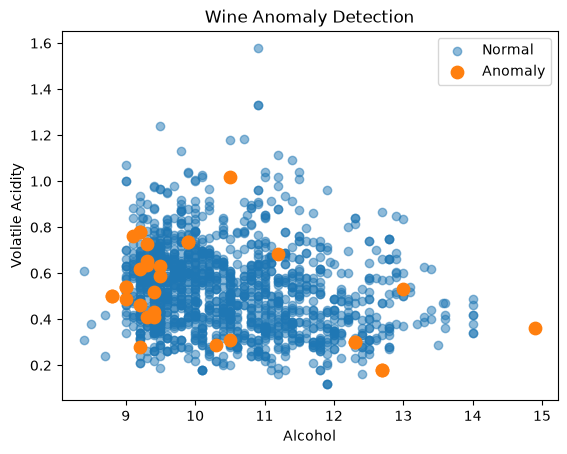

In [78]:
normal_wines = wine_results[wine_results["anomaly"] == 1]
anomalous_wines = wine_results[wine_results["anomaly"] == -1]

plt.scatter(
    normal_wines["alcohol"],
    normal_wines["volatile acidity"],
    alpha=0.5,
    label="Normal"
)

plt.scatter(
    anomalous_wines["alcohol"],
    anomalous_wines["volatile acidity"],
    s=80,
    label="Anomaly"
)

plt.xlabel("Alcohol")
plt.ylabel("Volatile Acidity")
plt.title("Wine Anomaly Detection")
plt.legend()
plt.show()

In [79]:
print("Number of trees:", len(real_model.estimators_))

Number of trees: 200


In [80]:
normal_index = np.where(real_predictions == 1)[0][0]
anomaly_index = np.argmin(real_scores)

print("Normal wine index:", normal_index)
print("Strongest anomaly index:", anomaly_index)

print("\nNormal wine:")
print(wine_df.iloc[normal_index])

print("\nStrongest anomaly:")
print(wine_df.iloc[anomaly_index])

Normal wine index: 0
Strongest anomaly index: 151

Normal wine:
fixed acidity            7.4000
volatile acidity         0.7000
citric acid              0.0000
residual sugar           1.9000
chlorides                0.0760
free sulfur dioxide     11.0000
total sulfur dioxide    34.0000
density                  0.9978
pH                       3.5100
sulphates                0.5600
alcohol                  9.4000
quality                  5.0000
Name: 0, dtype: float64

Strongest anomaly:
fixed acidity            9.2000
volatile acidity         0.5200
citric acid              1.0000
residual sugar           3.4000
chlorides                0.6100
free sulfur dioxide     32.0000
total sulfur dioxide    69.0000
density                  0.9996
pH                       2.7400
sulphates                2.0000
alcohol                  9.4000
quality                  4.0000
Name: 151, dtype: float64


In [81]:
tree = real_model.estimators_[0]

normal_path = tree.decision_path(
    features_wine_scaled[[normal_index]]
)

anomaly_path = tree.decision_path(
    features_wine_scaled[[anomaly_index]]
)

normal_depth = normal_path.sum() - 1
anomaly_depth = anomaly_path.sum() - 1

print("Normal wine path length:", normal_depth)
print("Anomaly wine path length:", anomaly_depth)

Normal wine path length: 8
Anomaly wine path length: 2


In [82]:
normal_path_lengths = []
anomaly_path_lengths = []

for tree in real_model.estimators_:
    
    normal_path = tree.decision_path(
        features_wine_scaled[[normal_index]]
    )
    
    anomaly_path = tree.decision_path(
        features_wine_scaled[[anomaly_index]]
    )
    
    normal_depth = normal_path.sum() - 1
    anomaly_depth = anomaly_path.sum() - 1
    
    normal_path_lengths.append(normal_depth)
    anomaly_path_lengths.append(anomaly_depth)

print("Normal path lengths:")
print(normal_path_lengths)

print("\nAnomaly path lengths:")
print(anomaly_path_lengths)

Normal path lengths:
[np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(4), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(7), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.

In [83]:
normal_average_path = np.mean(normal_path_lengths)
anomaly_average_path = np.mean(anomaly_path_lengths)

print("Normal average path length:", normal_average_path)
print("Anomaly average path length:", anomaly_average_path)

Normal average path length: 7.93
Anomaly average path length: 5.21


In [84]:
print("Quality distribution of anomalous wines:")

print(
    wine_results[
        wine_results["anomaly"] == -1
    ]["quality"].value_counts().sort_index()
)

Quality distribution of anomalous wines:
quality
4     2
5    19
6     8
7     3
Name: count, dtype: int64


In [85]:
normal_quality_mean = wine_results[
    wine_results["anomaly"] == 1
]["quality"].mean()

anomaly_quality_mean = wine_results[
    wine_results["anomaly"] == -1
]["quality"].mean()

print("Average quality of normal wines:", normal_quality_mean)
print("Average quality of anomalous wines:", anomaly_quality_mean)

Average quality of normal wines: 5.641352903637524
Average quality of anomalous wines: 5.375


In [86]:
contamination_values = [0.01, 0.02, 0.05, 0.10]

for contamination in contamination_values:
    
    test_model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42
    )
    
    test_predictions = test_model.fit_predict(features_wine_scaled)
    
    anomaly_count = np.sum(test_predictions == -1)
    
    print(
        "Contamination:", contamination,
        "→ Anomalies:", anomaly_count
    )

Contamination: 0.01 → Anomalies: 16
Contamination: 0.02 → Anomalies: 32
Contamination: 0.05 → Anomalies: 80
Contamination: 0.1 → Anomalies: 160


In [87]:
contamination_summary = {
    0.01: 16,
    0.02: 32,
    0.05: 80,
    0.10: 160
}

for contamination, count in contamination_summary.items():
    print(
        "Contamination:", contamination,
        "→ Anomalies:", count
    )

Contamination: 0.01 → Anomalies: 16
Contamination: 0.02 → Anomalies: 32
Contamination: 0.05 → Anomalies: 80
Contamination: 0.1 → Anomalies: 160


### Theoretical Aside: Understanding Evaluation Metrics on Labeled Data

> **Important Clarification:** In real-world unsupervised anomaly detection (such as our red wine dataset), ground-truth anomaly labels do not exist. To demonstrate how standard classification metrics (True Positives, False Positives, Precision, Recall, F1-Score) operate mathematically, the following cells use a miniature **synthetic toy dataset** with known artificial labels. These metrics evaluate the toy example only and **do not evaluate wine anomaly detection accuracy**.

In [88]:
evaluation_data = np.array([
    10, 11, 12, 10, 11,
    13, 12, 11, 10, 100
])

true_labels = np.array([
    0, 0, 0, 0, 0,
    0, 0, 0, 0, 1
])

print("Data:", evaluation_data)
print("True labels:", true_labels)

Data: [ 10  11  12  10  11  13  12  11  10 100]
True labels: [0 0 0 0 0 0 0 0 0 1]


In [89]:
evaluation_model = IsolationForest(
    n_estimators=200,
    contamination=0.1,
    random_state=42
)

evaluation_predictions = evaluation_model.fit_predict(
    evaluation_data.reshape(-1, 1)
)

print("Model predictions:")
print(evaluation_predictions)

Model predictions:
[ 1  1  1  1  1  1  1  1  1 -1]


In [90]:
predicted_labels = np.where(
    evaluation_predictions == -1,
    1,
    0
)

print("Predicted labels:")
print(predicted_labels)

Predicted labels:
[0 0 0 0 0 0 0 0 0 1]


In [91]:
tp = 0
tn = 0
fp = 0
fn = 0

for i in range(len(true_labels)):

    if true_labels[i] == 1 and predicted_labels[i] == 1:
        tp += 1

    elif true_labels[i] == 0 and predicted_labels[i] == 0:
        tn += 1

    elif true_labels[i] == 0 and predicted_labels[i] == 1:
        fp += 1

    elif true_labels[i] == 1 and predicted_labels[i] == 0:
        fn += 1

print("True Positives:", tp)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)

True Positives: 1
True Negatives: 9
False Positives: 0
False Negatives: 0


In [92]:
precision = tp / (tp + fp)

print("Precision:", precision)

Precision: 1.0


In [93]:
recall = tp / (tp + fn)

print("Recall:", recall)

Recall: 1.0


In [94]:
f1 = 2 * (precision * recall) / (precision + recall)

print("F1 Score:", f1)

F1 Score: 1.0


In [95]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [96]:
cm = confusion_matrix(
    true_labels,
    predicted_labels
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[9 0]
 [0 1]]


In [97]:
precision_sklearn = precision_score(
    true_labels,
    predicted_labels
)

recall_sklearn = recall_score(
    true_labels,
    predicted_labels
)

f1_sklearn = f1_score(
    true_labels,
    predicted_labels
)

print("Precision:", precision_sklearn)
print("Recall:", recall_sklearn)
print("F1 Score:", f1_sklearn)

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [98]:
wrong_predictions = np.array([
    0, 0, 0, 1, 0,
    0, 0, 0, 0, 1
])

print("True labels:")
print(true_labels)

print("\nWrong predictions:")
print(wrong_predictions)

True labels:
[0 0 0 0 0 0 0 0 0 1]

Wrong predictions:
[0 0 0 1 0 0 0 0 0 1]


In [99]:
tp = 0
tn = 0
fp = 0
fn = 0

for i in range(len(true_labels)):

    if true_labels[i] == 1 and wrong_predictions[i] == 1:
        tp += 1

    elif true_labels[i] == 0 and wrong_predictions[i] == 0:
        tn += 1

    elif true_labels[i] == 0 and wrong_predictions[i] == 1:
        fp += 1

    elif true_labels[i] == 1 and wrong_predictions[i] == 0:
        fn += 1

print("True Positives:", tp)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)

True Positives: 1
True Negatives: 8
False Positives: 1
False Negatives: 0


In [100]:
precision = tp / (tp + fp)

print("Precision:", precision)

Precision: 0.5


In [101]:
recall = tp / (tp + fn)

print("Recall:", recall)

Recall: 1.0


In [102]:
missed_predictions = np.array([
    0, 0, 0, 0, 0,
    0, 0, 0, 0, 0
])

print("True labels:")
print(true_labels)

print("\nMissed predictions:")
print(missed_predictions)

True labels:
[0 0 0 0 0 0 0 0 0 1]

Missed predictions:
[0 0 0 0 0 0 0 0 0 0]


In [103]:
tp = 0
tn = 0
fp = 0
fn = 0

for i in range(len(true_labels)):

    if true_labels[i] == 1 and missed_predictions[i] == 1:
        tp += 1

    elif true_labels[i] == 0 and missed_predictions[i] == 0:
        tn += 1

    elif true_labels[i] == 0 and missed_predictions[i] == 1:
        fp += 1

    elif true_labels[i] == 1 and missed_predictions[i] == 0:
        fn += 1

print("True Positives:", tp)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)

True Positives: 0
True Negatives: 9
False Positives: 0
False Negatives: 1


#### Edge Cases in Precision and Recall

In [104]:
wrong_precision = 0.5
wrong_recall = 1.0

wrong_f1 = 2 * (
    wrong_precision * wrong_recall
) / (
    wrong_precision + wrong_recall
)

print("F1 Score:", wrong_f1)

F1 Score: 0.6666666666666666


In [105]:
import sys

print(sys.executable)

C:\Users\THANGA PRAKASH\ML-learning\.venv\Scripts\python.exe


In [106]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU
CUDA version: 13.0


In [107]:
number = torch.tensor(7.0)

print(number)
print("Dimension:",number.ndim)
print("Shape:", number.shape)
print("Data type:", number.dtype)

tensor(7.)
Dimension: 0
Shape: torch.Size([])
Data type: torch.float32


In [108]:
number = torch.tensor([10.0,20.0,30.0])

print(number)
print("Dimension:", number.ndim)
print("Shape:", number.shape)
print("Number of elements:", number.numel())

tensor([10., 20., 30.])
Dimension: 1
Shape: torch.Size([3])
Number of elements: 3


In [109]:
transactions = torch.tensor([
    [300.0,2.0],
    [500.0,4.0],
    [1500.0,12.0]
])

print(transactions)
print("Dimension:", transactions.ndim)
print("Shape:", transactions.shape)
print("Number of elements:", transactions.numel())

tensor([[ 300.,    2.],
        [ 500.,    4.],
        [1500.,   12.]])
Dimension: 2
Shape: torch.Size([3, 2])
Number of elements: 6


In [110]:
a = torch.tensor([10.0,20.0,30.0])
b = torch.tensor([2.0,4.0,5.0])

print("Addition:", a + b)
print("Subtraction:", a - b)
print("Multipilcation:", a * b)
print("DIvision:", a / b)

Addition: tensor([12., 24., 35.])
Subtraction: tensor([ 8., 16., 25.])
Multipilcation: tensor([ 20.,  80., 150.])
DIvision: tensor([5., 5., 6.])


In [111]:
inputs = torch.tensor([
    [2.0,3.0],
    [4.0,5.0]
])

weight = torch.tensor([
    [0.1,0.2],
    [0.3,0.4]
])

results = inputs @ weight

print("inputs")
print(inputs)

print("weights")
print(weight)

print("Result")
print(results)

print("Result Shape:", results.shape)

inputs
tensor([[2., 3.],
        [4., 5.]])
weights
tensor([[0.1000, 0.2000],
        [0.3000, 0.4000]])
Result
tensor([[1.1000, 1.6000],
        [1.9000, 2.8000]])
Result Shape: torch.Size([2, 2])


In [112]:
inputs = torch.tensor([2.0, 3.0])

weights = torch.tensor([0.1,0.3])

bias = torch.tensor(0.5)

weighted_inputs = inputs * weights

weighted_sum = weighted_inputs.sum()

z = weighted_sum + bias

print("Inputs:", inputs)
print("Weights:", weights)
print("Weighted inputs:", weighted_inputs)
print("Weighted sum:", weighted_sum)
print("Bias:", bias)
print("Neuron output before activation:", z)

Inputs: tensor([2., 3.])
Weights: tensor([0.1000, 0.3000])
Weighted inputs: tensor([0.2000, 0.9000])
Weighted sum: tensor(1.1000)
Bias: tensor(0.5000)
Neuron output before activation: tensor(1.6000)


In [113]:
z = torch.tensor(1.6)

activated_output = torch.relu(z)

print("Before activation:", z)
print("After ReLu:", activated_output)

Before activation: tensor(1.6000)
After ReLu: tensor(1.6000)


In [114]:
import torch.nn as nn

neuron = nn.Linear(2, 1)

inputs = torch.tensor([2.0,3.0])

output = neuron(inputs)

print("Input:", inputs)
print("Weights:", neuron.weight)
print("Bias:", neuron.bias)
print("Output:", output)

Input: tensor([2., 3.])
Weights: Parameter containing:
tensor([[ 0.2439, -0.1725]], requires_grad=True)
Bias: Parameter containing:
tensor([0.2878], requires_grad=True)
Output: tensor([0.2579], grad_fn=<ViewBackward0>)


In [115]:
import torch.nn as nn
predictions = torch.tensor([6.0])

target = torch.tensor([10.0])

loss_funtion = nn.MSELoss()

loss = loss_funtion(predictions, target)

print("Predictions:", predictions)
print("Target:", target)
print("Loss:", loss)

Predictions: tensor([6.])
Target: tensor([10.])
Loss: tensor(16.)


In [116]:
weight = torch.tensor(3.0, requires_grad=True)

input_value = torch.tensor(2.0)
target = torch.tensor(10.0)

prediction = weight * input_value

loss = (prediction - target) ** 2

print("Weight:", weight)
print("Prediction:", prediction)
print("Loss:", loss)

Weight: tensor(3., requires_grad=True)
Prediction: tensor(6., grad_fn=<MulBackward0>)
Loss: tensor(16., grad_fn=<PowBackward0>)


In [117]:

loss.backward()

print("Weight:", weight)
print("Gradient:", weight.grad)


Weight: tensor(3., requires_grad=True)
Gradient: tensor(-16.)


In [118]:
learning_rate = 0.1

with torch.no_grad():
    weight -= learning_rate * weight.grad

print("Updated weight:", weight)

Updated weight: tensor(4.6000, requires_grad=True)


In [119]:

prediction = weight * input_value

loss = (prediction - target) ** 2

print("Updated weight:", weight.item())
print("New prediction:", prediction.item())
print("New loss:", loss.item())


Updated weight: 4.599999904632568
New prediction: 9.199999809265137
New loss: 0.6400002837181091


In [120]:

print("Gradient before backward:", weight.grad)

prediction = weight * input_value
loss = (prediction - target) ** 2

loss.backward()

print("Gradient after backward:", weight.grad)


Gradient before backward: tensor(-16.)
Gradient after backward: tensor(-19.2000)


In [121]:
weight.grad.zero_()

print("Gradient after clearing:", weight.grad)
print("Weight remains:", weight.item())

Gradient after clearing: tensor(0.)
Weight remains: 4.599999904632568


In [122]:
import torch.optim as optim

optimizer = optim.SGD([weight], lr=0.1)

print("Current weight:", weight.item())
print("Learning rate:", optimizer.param_groups[0]["lr"])

Current weight: 4.599999904632568
Learning rate: 0.1


In [123]:
#Calculate the predictions and loss
prediction = weight * input_value

loss = (prediction - target) ** 2

#Clear old gradients
optimizer.zero_grad()

#Calculate the gradients
loss.backward()

#Update the weight
optimizer.step()

print("Updated weight:", weight.item())

Updated weight: 4.920000076293945


In [124]:

prediction = weight * input_value
loss = (prediction - target) ** 2

print("Updated weight:", weight.item())
print("New prediction:", prediction.item())
print("New loss:", loss.item())


Updated weight: 4.920000076293945
New prediction: 9.84000015258789
New loss: 0.025599950924515724


In [125]:

import torch
import torch.nn as nn
import torch.optim as optim

weight = torch.tensor(3.0, requires_grad=True)

input_value = torch.tensor(2.0)
target = torch.tensor(10.0)

optimizer = optim.SGD([weight], lr=0.1)

print("Starting weight:", weight.item())


Starting weight: 3.0


In [126]:
for epoch in range(10):
    prediction = weight * input_value
    loss = (prediction - target) ** 2

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print("Epoch:", epoch + 1,
          "| Prediction:", prediction.item(),
          "| Loss:", loss.item())


Epoch: 1 | Prediction: 6.0 | Loss: 16.0
Epoch: 2 | Prediction: 9.199999809265137 | Loss: 0.6400002837181091
Epoch: 3 | Prediction: 9.84000015258789 | Loss: 0.025599950924515724
Epoch: 4 | Prediction: 9.968000411987305 | Loss: 0.0010239736875519156
Epoch: 5 | Prediction: 9.993599891662598 | Loss: 4.096138582099229e-05
Epoch: 6 | Prediction: 9.998720169067383 | Loss: 1.63796721608378e-06
Epoch: 7 | Prediction: 9.999744415283203 | Loss: 6.53235474601388e-08
Epoch: 8 | Prediction: 9.999948501586914 | Loss: 2.6520865503698587e-09
Epoch: 9 | Prediction: 9.99998950958252 | Loss: 1.1004885891452432e-10
Epoch: 10 | Prediction: 9.999998092651367 | Loss: 3.637978807091713e-12


In [127]:

total_samples = 100
batch_size = 10

iterations_per_epoch = total_samples // batch_size

print("Total samples:", total_samples)
print("Batch size:", batch_size)
print("Iterations per epoch:", iterations_per_epoch)


Total samples: 100
Batch size: 10
Iterations per epoch: 10


In [128]:

print("Original wine dataset shape:", wine_df.shape)
print("Scaled feature shape:", features_wine_scaled.shape)
print("Number of input features:", features_wine_scaled.shape[1])


Original wine dataset shape: (1599, 12)
Scaled feature shape: (1599, 11)
Number of input features: 11


In [129]:
from sklearn.model_selection import train_test_split

features_wine = wine_df.drop("quality", axis=1)

X_train_raw, X_test_raw = train_test_split(
        features_wine,
        test_size=0.2,
        random_state=42
)

print("Training set shape:", X_train_raw.shape)
print("Testing set shape:", X_test_raw.shape)

Training set shape: (1279, 11)
Testing set shape: (320, 11)


In [130]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("Training mean of first feature:", X_train_scaled[:, 0].mean())


Scaled training shape: (1279, 11)
Scaled testing shape: (320, 11)
Training mean of first feature: -1.1110910645193122e-16


In [131]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

print("Training tensor shape:", X_train_tensor.shape)
print("Testing tensor shape:", X_test_tensor.shape)
print("Training tensor dtype:", X_train_tensor.dtype)

Training tensor shape: torch.Size([1279, 11])
Testing tensor shape: torch.Size([320, 11])
Training tensor dtype: torch.float32


### Reproducibility Controls for PyTorch Data Loading and Modeling
To minimize stochastic divergence across repeated training runs, we establish a consistent random seed (`SEED = 42`) across Python's `random`, NumPy, and PyTorch. We also supply a dedicated PyTorch `Generator` to `DataLoader` to control mini-batch shuffling.

> **Note on Reproducibility:** Setting random seeds controls pseudo-random number sequences across data loading and weight initialization, significantly reducing run-to-run variation. However, seeds reduce variation but do not guarantee bit-for-bit identical floating-point results across different hardware architectures, CUDA runtimes, or operating systems due to parallel execution non-associativity.

In [132]:
import random
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Consistent random seed controls
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

train_dataset = TensorDataset(X_train_tensor)

# Dedicated generator for reproducible DataLoader shuffling
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=loader_generator
)

print("Number of training sample:", len(train_dataset))
print("Number of batches:", len(train_loader))


Number of training sample: 1279
Number of batches: 40


In [133]:
for batch in train_loader:
    batch_data = batch[0]

    print("Batch Shape:", batch_data.shape)
    print("first wine sample:", batch_data[0])
    print("Number of samples in the batch:", batch_data.size())

Batch Shape: torch.Size([32, 11])
first wine sample: tensor([-0.3038,  0.4991, -1.1387, -0.1780, -0.1916, -0.9580, -0.8703,  0.3105,
        -0.1406, -0.1720, -1.0625])
Number of samples in the batch: torch.Size([32, 11])
Batch Shape: torch.Size([32, 11])
first wine sample: tensor([ 3.8735, -1.7888,  0.8575, -0.2477, -0.2727, -0.5700, -0.6881,  1.7658,
        -1.5696,  1.0312, -1.1576])
Number of samples in the batch: torch.Size([32, 11])
Batch Shape: torch.Size([32, 11])
first wine sample: tensor([-0.3038,  1.2803, -1.1899, -0.1780,  0.0720, -0.0850,  0.2230,  0.1218,
        -0.3355, -0.0574, -0.5874])
Number of samples in the batch: torch.Size([32, 11])
Batch Shape: torch.Size([32, 11])
first wine sample: tensor([-1.0581,  0.5549,  0.2945, -0.5264, -0.5972,  0.0120, -0.5666, -0.7891,
         0.3141, -0.1147, -0.3023])
Number of samples in the batch: torch.Size([32, 11])
Batch Shape: torch.Size([32, 11])
first wine sample: tensor([-0.4199, -0.3937, -0.8316,  0.0310, -0.1916, -0.376

## 5. Deep Learning-Based Anomaly Detection: PyTorch Autoencoder

An Autoencoder compresses input data into a lower-dimensional bottleneck representation and reconstructs it. Because the network learns the manifold of normal data, anomalous patterns produce significantly higher reconstruction errors.

In [134]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(11, 8),
            nn.ReLU(),
            nn.Linear(8, 4)
        )

        self.decoder = nn.Sequential(
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 11)
        )

    def forward(self, x):
        compressed = self.encoder(x)
        reconstructed = self.decoder(compressed)
        return reconstructed


### Autoencoder Architecture Definition and Instantiation
Instantiating a symmetric feedforward neural network (`11 -> 8 -> 4 -> 8 -> 11`) with ReLU activations.

In [135]:
# Set seed immediately prior to model instantiation for deterministic weight initialization
torch.manual_seed(SEED)

model = Autoencoder()
print(model)


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=11, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=4, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=11, bias=True)
  )
)


In [136]:
total_parameters = 0

for parameter in model.parameters():
    if parameter.requires_grad:
        total_parameters += parameter.numel()
print("Total trainable parameters:", total_parameters)

Total trainable parameters: 271


In [137]:
batch = next(iter(train_loader))
batch_data = batch[0]

reconstructed = model(batch_data)

print("Original batch shape:", batch_data.shape)
print("Reconstructed batch shape:", reconstructed.shape)

print("Original first sample:")
print(batch_data[0])

print("Reconstructed first sample:")
print(reconstructed[0])

Original batch shape: torch.Size([32, 11])
Reconstructed batch shape: torch.Size([32, 11])
Original first sample:
tensor([ 2.2490, -0.4495,  1.1134, -0.8051, -0.2727, -1.2490, -1.2347,  0.0679,
        -1.1799, -0.1720, -0.0172])
Reconstructed first sample:
tensor([ 0.0814, -0.0647,  0.3786, -0.2924, -0.0559,  0.1937, -0.1148, -0.0923,
        -0.3040, -0.4724,  0.0609], grad_fn=<SelectBackward0>)


In [138]:
loss_function = nn.MSELoss()

loss = loss_function(reconstructed, batch_data)

print("initial reconstructed loss:", loss.item())

initial reconstructed loss: 1.0139789581298828


In [139]:
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Optimizer:", optimizer)
print("learning rate:", optimizer.param_groups[0]["lr"])

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
learning rate: 0.001


In [140]:
model.train()

print("Model is in training mode:", model.training)

Model is in training mode: True


In [141]:
# Explicit demonstration of clearing PyTorch optimizer gradient buffers
optimizer.zero_grad()
print("Gradients cleared successfully")

Gradients cleared successfully


In [142]:
optimizer.zero_grad()

reconstructed = model(batch_data)
loss = loss_function(reconstructed, batch_data)

loss.backward()

print("Reconstructed loss:", loss.item())
print("Gradients calculated:", model.encoder[0].weight.grad is not None)

Reconstructed loss: 1.0139789581298828
Gradients calculated: True


In [143]:
optimizer.step()

print("Parameters updated successfully")
print("current reconstructed loss:", loss.item())

Parameters updated successfully
current reconstructed loss: 1.0139789581298828


In [144]:
with torch.no_grad():
    reconstructed_after_update = model(batch_data)
    loss_after_update = loss_function(reconstructed_after_update, batch_data)
print("loss before update:", loss.item())
print("loss after update:", loss_after_update.item())

loss before update: 1.0139789581298828
loss after update: 1.01145339012146


#### Single-Epoch Training Pass Demonstration
The cell below executes a single training epoch across all minibatches to demonstrate the complete forward pass, loss calculation, backward gradient computation, and parameter update cycle before launching the full 20-epoch training loop.

In [145]:
model.train()

total_loss = 0.0

for batch in train_loader:
    batch_data = batch[0]

    optimizer.zero_grad()

    reconstructed = model(batch_data)

    loss = loss_function(reconstructed, batch_data)

    loss.backward()

    optimizer.step()

    total_loss += loss.item()

average_loss = total_loss / len(train_loader)

print("Average training loss:", average_loss)

Average training loss: 1.0336833775043488


#### Full 20-Epoch Training Loop
In the preceding educational walkthrough, we demonstrated PyTorch mechanics via a single mini-batch step (Cell 170) and a complete single-epoch pass (Cell 173), both of which performed gradient updates on `model`. The 20-epoch training loop below continues training from this updated parameter state, iterating across all minibatches to steadily minimize reconstruction loss.

In [146]:
num_epochs = 20

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for batch in train_loader:
        batch_data = batch[0]

        optimizer.zero_grad()

        reconstructed = model(batch_data)
        loss = loss_function(reconstructed, batch_data)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {average_loss:.4f}")

Epoch [1/20], Loss: 0.9772
Epoch [2/20], Loss: 0.8913
Epoch [3/20], Loss: 0.7768
Epoch [4/20], Loss: 0.6891
Epoch [5/20], Loss: 0.6255
Epoch [6/20], Loss: 0.5760
Epoch [7/20], Loss: 0.5470
Epoch [8/20], Loss: 0.5279
Epoch [9/20], Loss: 0.5131
Epoch [10/20], Loss: 0.5000
Epoch [11/20], Loss: 0.4871
Epoch [12/20], Loss: 0.4746
Epoch [13/20], Loss: 0.4622
Epoch [14/20], Loss: 0.4504
Epoch [15/20], Loss: 0.4376
Epoch [16/20], Loss: 0.4255
Epoch [17/20], Loss: 0.4128
Epoch [18/20], Loss: 0.4008
Epoch [19/20], Loss: 0.3898
Epoch [20/20], Loss: 0.3782


In [147]:
model.eval()

with torch.no_grad():
    test_reconstructed = model(X_test_tensor)
    test_loss = loss_function(test_reconstructed, X_test_tensor)

print("Original test shape:", X_test_tensor.shape)
print("Reconstructed test shape:", test_reconstructed.shape)
print("Test reconstruction loss:", test_loss.item())

Original test shape: torch.Size([320, 11])
Reconstructed test shape: torch.Size([320, 11])
Test reconstruction loss: 0.33813780546188354


### Exploratory Inspection of Test Reconstruction Errors
Below, we evaluate the trained autoencoder on the held-out test set (`X_test_tensor`) and inspect the distribution of test reconstruction errors as an exploratory preview. Note that this test inspection is exploratory only; the decision threshold itself is calculated strictly from the **training set** reconstruction errors in the subsequent cell.

In [148]:
with torch.no_grad():
    squared_errors = (test_reconstructed - X_test_tensor) **2
    reconstruction_errors = squared_errors.mean(dim=1)


print("Number of test samples:", len(reconstruction_errors))
print("First 10 reconstruction errors:")
print(reconstruction_errors[:10])

Number of test samples: 320
First 10 reconstruction errors:
tensor([0.1478, 0.1774, 0.4640, 0.1611, 0.0457, 0.2060, 0.2943, 0.0995, 0.0972,
        0.0748])


In [149]:
print("Minimum reconstruction error:", reconstruction_errors.min().item())
print("Maximum reconstruction error:", reconstruction_errors.max().item())
print("Average reconstruction error:", reconstruction_errors.mean().item())
print("Median reconstruction error:", reconstruction_errors.median().item())

Minimum reconstruction error: 0.03887083753943443
Maximum reconstruction error: 5.40092658996582
Average reconstruction error: 0.33813783526420593
Median reconstruction error: 0.2093523144721985


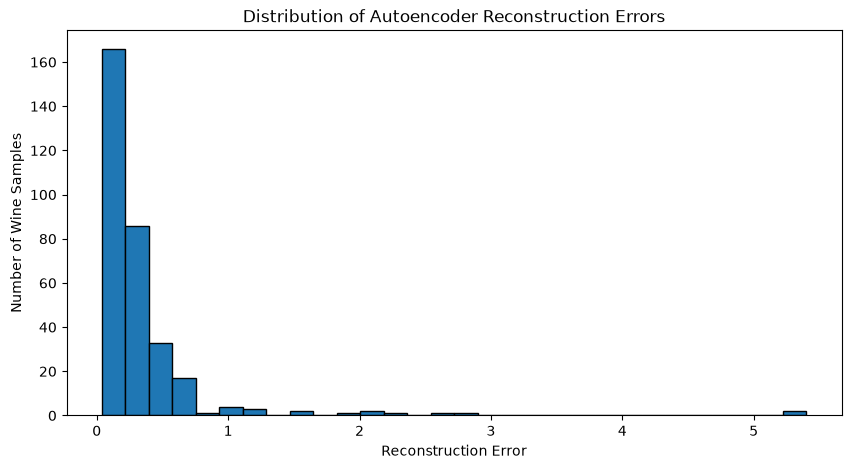

In [150]:
import matplotlib.pyplot as plt

errors = reconstruction_errors.cpu().numpy()

plt.figure(figsize=(10, 5))
plt.hist(errors, bins=30, edgecolor="black")

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Wine Samples")
plt.title("Distribution of Autoencoder Reconstruction Errors")

plt.show()

### Anomaly Decision Threshold Calculation (Training Distribution)
To establish an objective anomaly decision boundary without data leakage, we compute reconstruction errors on the **training set** (`X_train_tensor`) and define the threshold as the **95th percentile** of training errors. Only test samples with reconstruction errors exceeding this training-derived threshold are flagged as candidate anomalies.

In [151]:
with torch.no_grad():
    train_reconstructed = model(X_train_tensor)
    train_squared_errors = (train_reconstructed - X_train_tensor) ** 2
    train_reconstruction_errors = train_squared_errors.mean(dim=1)

threshold = torch.quantile(train_reconstruction_errors, 0.95)

print("Anomaly threshold:", threshold.item())

Anomaly threshold: 1.0455700159072876


In [152]:
anomaly_predictions = reconstruction_errors > threshold

print("Total test samples:", len(reconstruction_errors))
print("Potential anomalies:", anomaly_predictions.sum().item())
print("Potential normal samples:", (~anomaly_predictions).sum().item())

Total test samples: 320
Potential anomalies: 13
Potential normal samples: 307


In [153]:
anomaly_indices = torch.where(anomaly_predictions)[0]

anomalous_wines = X_test_raw.iloc[
    anomaly_indices.cpu().numpy()
].copy()

anomalous_wines["reconstruction_error"] = (
    reconstruction_errors[anomaly_indices].cpu().numpy()
)

print("Potentially anomalous wine samples:")
print(anomalous_wines.sort_values(
    by="reconstruction_error",
    ascending=False
))

Potentially anomalous wine samples:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1079            7.9             0.300         0.68             8.3      0.050   
1244            5.9             0.290         0.25            13.4      0.067   
451             8.4             0.370         0.53             1.8      0.413   
692             8.6             0.490         0.51             2.0      0.422   
614             9.2             0.755         0.18             2.2      0.148   
324            10.0             0.490         0.20            11.0      0.071   
494             6.5             0.390         0.23             8.3      0.051   
649             6.7             0.420         0.27             8.6      0.068   
861             5.8             1.010         0.66             2.0      0.039   
240             8.9             0.635         0.37             1.7      0.263   
353            13.5             0.530         0.79             4.8      0

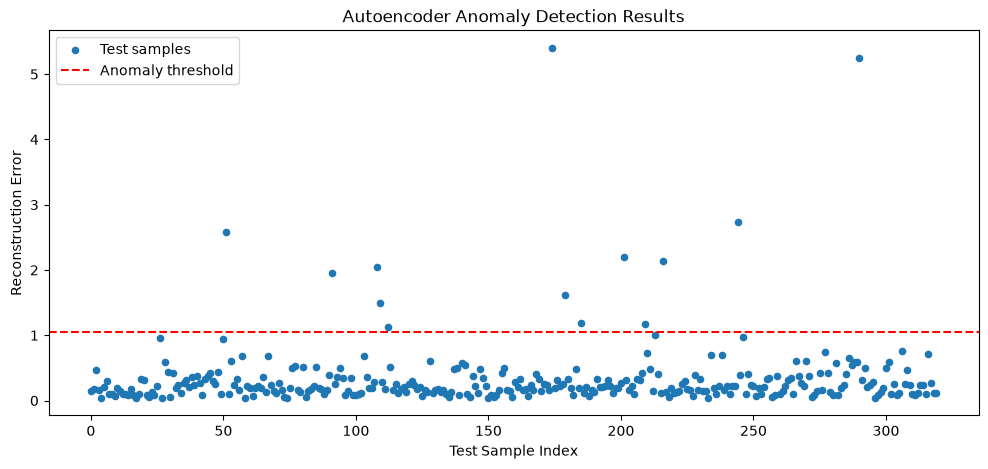

In [154]:
plt.figure(figsize=(12, 5))

plt.scatter(
    range(len(reconstruction_errors)),
    errors,
    s=20,
    label="Test samples"
)

plt.axhline(
    y=threshold.item(),
    color="red",
    linestyle="--",
    label="Anomaly threshold"
)

plt.xlabel("Test Sample Index")
plt.ylabel("Reconstruction Error")
plt.title("Autoencoder Anomaly Detection Results")
plt.legend()

plt.show()

In [155]:
print("Test samples:", len(X_test_raw))
print("Test feature count:", X_test_raw.shape[1])
print("Autoencoder predictions:", len(anomaly_predictions))
print("Autoencoder potential anomalies:", anomaly_predictions.sum().item())

Test samples: 320
Test feature count: 11
Autoencoder predictions: 320
Autoencoder potential anomalies: 13


## 6. Multi-Method Evaluation and Cross-Model Comparison

We systematically compare anomaly predictions across all three paradigms (Z-score, Isolation Forest, and PyTorch Autoencoder) on the held-out 320 test samples.

In [156]:
import numpy as np

test_features_scaled = scaler.transform(X_test_raw)

test_z_scores = np.abs(test_features_scaled)

zscore_predictions = (test_z_scores > 3).any(axis=1)

print("Total test samples:", len(zscore_predictions))
print("Potential anomalies using Z-score:", zscore_predictions.sum())
print("Potential normal samples:", (~zscore_predictions).sum())

Total test samples: 320
Potential anomalies using Z-score: 31
Potential normal samples: 289


#### Isolation Forest on Held-Out Test Set
For a fair comparison across methods, we train an Isolation Forest on the training split with `contamination=0.05` (identifying the top 5% most anomalous candidates), directly aligning with the Autoencoder's 95th percentile upper-tail reconstruction error threshold.

In [157]:
from sklearn.ensemble import IsolationForest

isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

isolation_model.fit(X_train_scaled)

isolation_predictions = isolation_model.predict(test_features_scaled)

isolation_predictions = isolation_predictions == -1

print("Total test samples:", len(isolation_predictions))
print("Potential anomalies using Isolation Forest:", isolation_predictions.sum())
print("Potential normal samples:", (~isolation_predictions).sum())

Total test samples: 320
Potential anomalies using Isolation Forest: 19
Potential normal samples: 301


In [158]:
anomaly_predictions_np = anomaly_predictions.cpu().numpy()

print("Flagged by all three methods:",
      (zscore_predictions & isolation_predictions & anomaly_predictions_np).sum())

print("Flagged by Z-score and Isolation Forest:",
      (zscore_predictions & isolation_predictions).sum())

print("Flagged by Z-score and Autoencoder:",
      (zscore_predictions & anomaly_predictions_np).sum())

print("Flagged by Isolation Forest and Autoencoder:",
      (isolation_predictions & anomaly_predictions_np).sum())

Flagged by all three methods: 8
Flagged by Z-score and Isolation Forest: 14
Flagged by Z-score and Autoencoder: 12
Flagged by Isolation Forest and Autoencoder: 9


In [159]:
zscore_only = (
    zscore_predictions
    & ~isolation_predictions
    & ~anomaly_predictions_np
)

isolation_only = (
    isolation_predictions
    & ~zscore_predictions
    & ~anomaly_predictions_np
)

autoencoder_only = (
    anomaly_predictions_np
    & ~zscore_predictions
    & ~isolation_predictions
)

print("Flagged only by Z-score:", zscore_only.sum())
print("Flagged only by Isolation Forest:", isolation_only.sum())
print("Flagged only by Autoencoder:", autoencoder_only.sum())

Flagged only by Z-score: 13
Flagged only by Isolation Forest: 4
Flagged only by Autoencoder: 0


In [160]:
comparison_summary = pd.DataFrame({
    "Method": [
        "Z-score",
        "Isolation Forest",
        "Autoencoder"
    ],
    "Anomalies Detected": [
        zscore_predictions.sum(),
        isolation_predictions.sum(),
        anomaly_predictions_np.sum()
    ],
    "Normal Samples": [
        (~zscore_predictions).sum(),
        (~isolation_predictions).sum(),
        (~anomaly_predictions_np).sum()
    ]
})

print(comparison_summary)

             Method  Anomalies Detected  Normal Samples
0           Z-score                  31             289
1  Isolation Forest                  19             301
2       Autoencoder                  13             307


In [161]:
comparison_details = pd.DataFrame({
    "Z-score": zscore_predictions,
    "Isolation Forest": isolation_predictions,
    "Autoencoder": anomaly_predictions_np
}, index=X_test_raw.index)

comparison_details["Number of Methods"] = (
    comparison_details.sum(axis=1)
)

print("Flagged by at least two methods:")
print(
    comparison_details[
        comparison_details["Number of Methods"] >= 2
    ].sort_values(
        by="Number of Methods",
        ascending=False
    )
)

Flagged by at least two methods:
      Z-score  Isolation Forest  Autoencoder  Number of Methods
692      True              True         True                  3
649      True              True         True                  3
353      True              True         True                  3
451      True              True         True                  3
614      True              True         True                  3
1079     True              True         True                  3
324      True              True         True                  3
1244     True              True         True                  3
1269     True              True        False                  2
926      True             False         True                  2
494      True             False         True                  2
861     False              True         True                  2
240      True             False         True                  2
588      True              True        False                  2
584    

In [162]:
common_anomalies = comparison_details[
    comparison_details["Number of Methods"] == 3
].index

common_anomalies_data = wine_df.loc[common_anomalies]

print("Wines flagged by all three methods:")
print(common_anomalies_data)

Wines flagged by all three methods:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
692             8.6             0.490         0.51             2.0      0.422   
649             6.7             0.420         0.27             8.6      0.068   
1079            7.9             0.300         0.68             8.3      0.050   
353            13.5             0.530         0.79             4.8      0.120   
614             9.2             0.755         0.18             2.2      0.148   
324            10.0             0.490         0.20            11.0      0.071   
451             8.4             0.370         0.53             1.8      0.413   
1244            5.9             0.290         0.25            13.4      0.067   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
692                  16.0                  62.0  0.99790  3.03       1.17   
649                  24.0                 148.0  0.99480  3.16       0.57   
107

In [163]:
common_features_scaled = scaler.transform(
    common_anomalies_data.drop("quality", axis=1)
)

# Simplified: common_features_scaled is already standardized by the fitted training scaler
common_z_scores = np.abs(common_features_scaled)

common_z_score_df = pd.DataFrame(
    common_z_scores,
    columns=features_wine.columns,
    index=common_anomalies_data.index
)

print(common_z_score_df.round(2))


      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
692            0.16              0.23         1.22            0.39       6.76   
649            0.94              0.62         0.01            4.21       0.41   
1079           0.25              1.29         2.09            4.00       0.78   
353            3.00              0.00         2.65            1.56       0.64   
614            0.51              1.25         0.47            0.25       1.21   
324            0.97              0.23         0.37            5.88       0.35   
451            0.04              0.90         1.32            0.53       6.58   
1244           1.41              1.34         0.12            7.56       0.43   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
692                  0.01                  0.47     0.61  1.83       2.92   
649                  0.79                  3.08     1.06  0.99       0.52   
1079                 2.10              

In [164]:
largest_deviation = common_z_score_df.max(axis=1)

most_unusual_feature = common_z_score_df.idxmax(axis=1)

feature_summary = pd.DataFrame({
    "Most Unusual Feature": most_unusual_feature,
    "Largest Standardized Deviation": largest_deviation
})

print(feature_summary.round(2))

      Most Unusual Feature  Largest Standardized Deviation
692              chlorides                            6.76
649         residual sugar                            4.21
1079  total sulfur dioxide                            7.03
353          fixed acidity                            3.00
614              sulphates                            4.01
324         residual sugar                            5.88
451              chlorides                            6.58
1244        residual sugar                            7.56


In [165]:
print("ANOMALY DETECTION — FINAL SUMMARY")
print("-" * 40)

print("Test samples:", len(X_test_raw))
print("Z-score anomalies:", int(zscore_predictions.sum()))
print("Isolation Forest anomalies:", int(isolation_predictions.sum()))
print("Autoencoder anomalies:", int(anomaly_predictions_np.sum()))

print(
    "Flagged by all three:",
    int(
        (
            zscore_predictions
            & isolation_predictions
            & anomaly_predictions_np
        ).sum()
    )
)

print(
    "Flagged by at least two:",
    int((comparison_details["Number of Methods"] >= 2).sum())
)

ANOMALY DETECTION — FINAL SUMMARY
----------------------------------------
Test samples: 320
Z-score anomalies: 31
Isolation Forest anomalies: 19
Autoencoder anomalies: 13
Flagged by all three: 8
Flagged by at least two: 19
